In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor 
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error


In [19]:
data = pd.read_csv('Student_Performance.csv')
df = data.copy()
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [20]:
# data prep
# 1. Renaming columns
df.columns = df.columns.str.lower().str.replace(' ', '_')

df.columns

Index(['hours_studied', 'previous_scores', 'extracurricular_activities',
       'sleep_hours', 'sample_question_papers_practiced', 'performance_index'],
      dtype='str')

In [21]:
# 2. Converting the categorical variable to int
df.extracurricular_activities = df.extracurricular_activities.map({'Yes': 1, 'No': 0})

In [22]:
# 3. Check for missing values
df.isnull().sum()

hours_studied                       0
previous_scores                     0
extracurricular_activities          0
sleep_hours                         0
sample_question_papers_practiced    0
performance_index                   0
dtype: int64

In [23]:
# 4. Checking for duplicates
df.duplicated().sum()

df = df.drop_duplicates().reset_index(drop=True)

<Axes: xlabel='performance_index', ylabel='Count'>

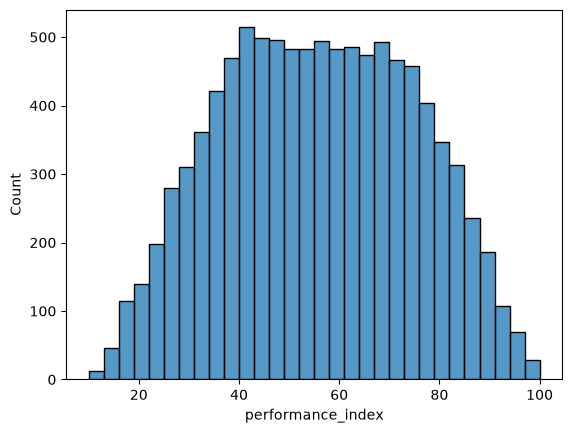

In [24]:
# eda
# 1. Checking the distribution of the target variable

sns.histplot(df.performance_index, bins = 30)

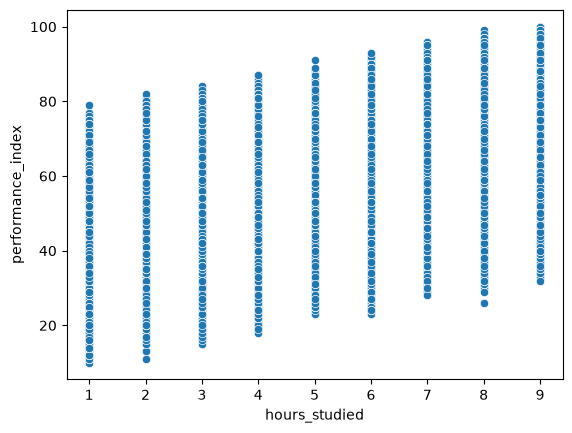

In [25]:
# 2. Visualizing the relationship between the features and the target variable
sns.scatterplot(x='hours_studied', y='performance_index', data=df)
plt.show()

In [26]:
# 3. checking group aggregate of performance_index by extracurricular_activities
df.groupby('extracurricular_activities')['performance_index'].mean().sort_values(ascending = False)

extracurricular_activities
1    55.722529
0    54.720818
Name: performance_index, dtype: float64

In [27]:
# 4. Checking the correlation between features and the target variable
df.corr()['performance_index'].sort_values(ascending = False)

performance_index                   1.000000
previous_scores                     0.915135
hours_studied                       0.375332
sleep_hours                         0.050352
sample_question_papers_practiced    0.043436
extracurricular_activities          0.026075
Name: performance_index, dtype: float64

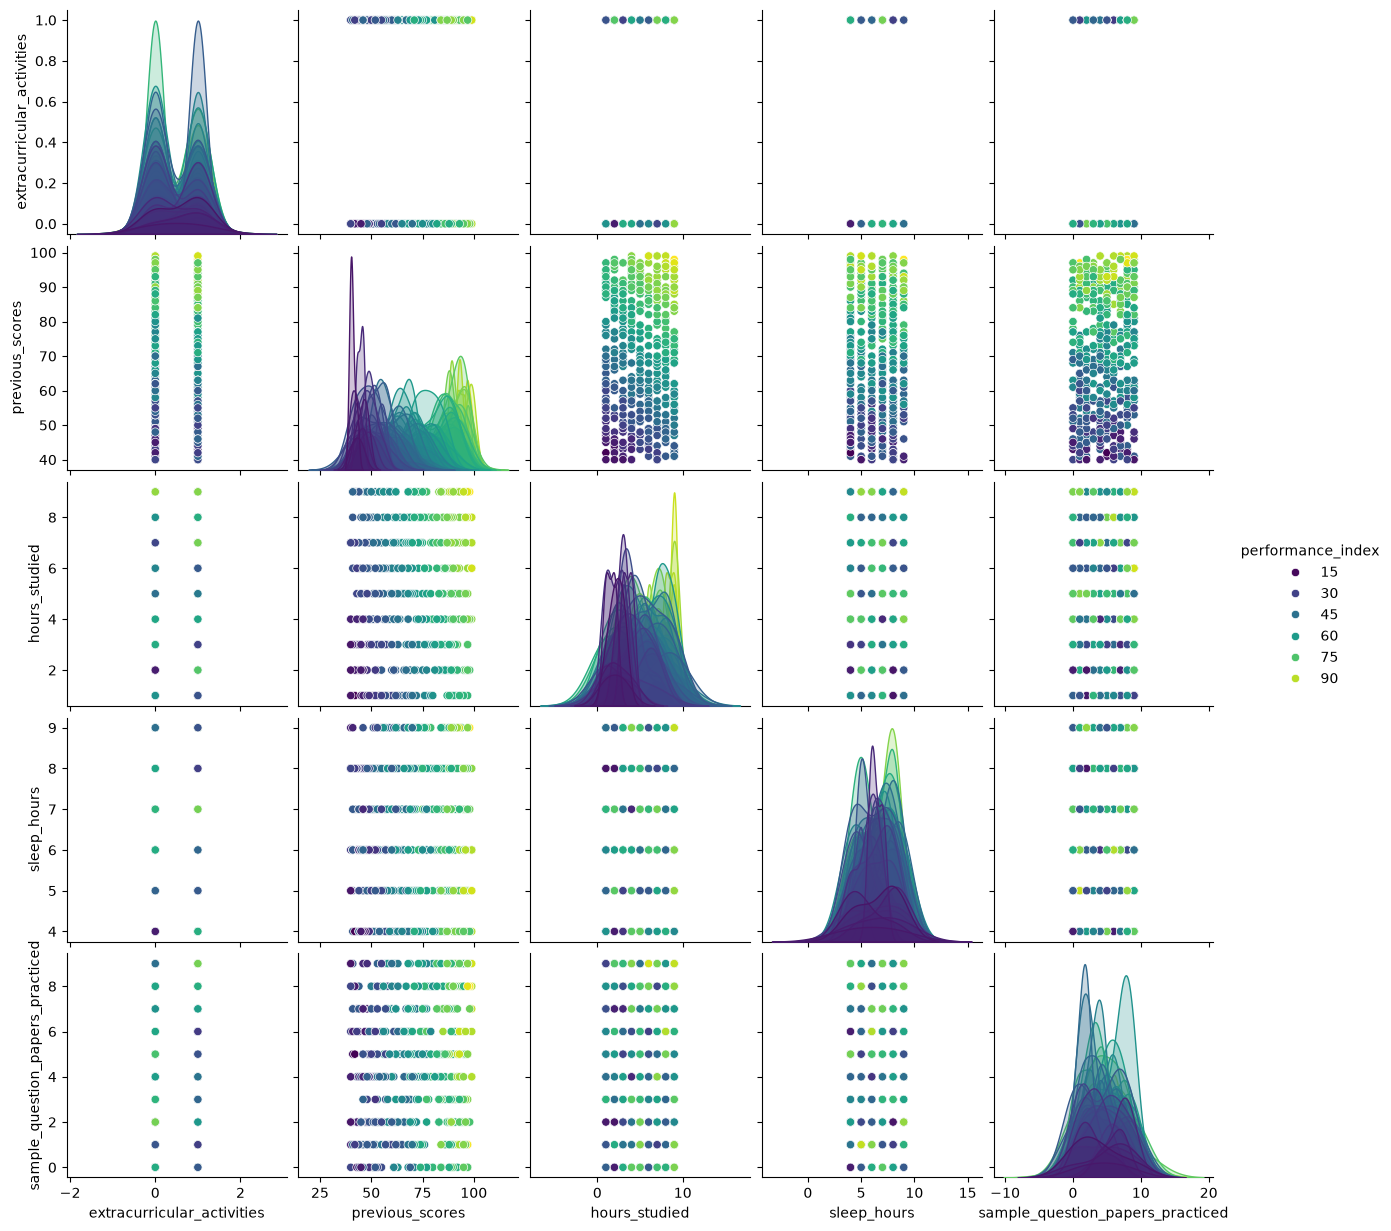

In [28]:
# 5. checking the relationship between combined features and the target variable

cols = [
    'extracurricular_activities', 
    'previous_scores', 
    'hours_studied', 
    'sleep_hours', 
    'sample_question_papers_practiced', 
    'performance_index'
]

sns.pairplot(df[cols].sample(500, random_state=42), hue='performance_index', palette='viridis')
plt.show()

In [29]:
# Splitting data
X = df.drop('performance_index', axis = 1)
y = df['performance_index']

# First split into train and test sets
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Second split into train and val sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42
)

In [30]:
# Trying first model - Linear Regression
model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_val)

rmse = root_mean_squared_error(y_val, y_pred)

print(rmse)

2.0190190109649686


In [32]:
# Feature engineering
# 1. creating a new feature - score per hour (previous_scores / hours_studied)
X_train_copy = X_train.copy()

X_val_copy = X_val.copy()

X_train_copy['score_per_hour'] = X_train_copy['previous_scores'] / X_train_copy['hours_studied']

X_val_copy['score_per_hour'] = X_val_copy['previous_scores'] / X_val_copy['hours_studied']

model.fit(X_train_copy, y_train)

y_pred_1 = model.predict(X_val_copy)

rmse_1 = root_mean_squared_error(y_val, y_pred_1)

print(rmse_1)

2.0190412937389217


Dropping score per hour because it does not improve the model. Moving on to dropping the 'sample_question_papers_practiced' column, a weak feature, to see if it improves performance 

In [33]:
# 2. Dropping sample_question_papers_practiced'
X_train_copy = X_train_copy.drop(['sample_question_papers_practiced', 'score_per_hour'], axis=1)

X_val_copy = X_val_copy.drop(['sample_question_papers_practiced', 'score_per_hour'], axis=1)

model.fit(X_train_copy, y_train)

y_pred_2 = model.predict(X_val_copy)

rmse_2 = root_mean_squared_error(y_val, y_pred_2)

print(rmse_2)

2.0744710271979763


Keeping 'sample_question_papers_practiced'. I dscovered it's relevant to the target as shown by the increase in rmse

In [37]:
# Trying out different models - Decision Tree Regressor and Random Forest Regressor
depths = [4, 6, 8, 10, 12]

for d in depths:
    model_1 = DecisionTreeRegressor(max_depth=d, random_state=42)
    model_1.fit(X_train, y_train)
    rmse_1 = root_mean_squared_error(y_val, model_1.predict(X_val))
    print(f"depth={d}, rmse = {rmse_1}")

for d in depths:
    model_2 = RandomForestRegressor(n_estimators=100, max_depth=d, random_state=42, n_jobs=-1)
    model_2.fit(X_train, y_train)
    rmse_2 = root_mean_squared_error(y_val, model_2.predict(X_val))
    print(f"depth={d}, rmse = {rmse_2}")

depth=4, rmse = 4.824894352308345
depth=6, rmse = 3.0949571034929733
depth=8, rmse = 2.526021046484259
depth=10, rmse = 2.580241122484757
depth=12, rmse = 2.908453284469151
depth=4, rmse = 3.9542148855505164
depth=6, rmse = 2.580016129402483
depth=8, rmse = 2.2600412134776966
depth=10, rmse = 2.2515138971865762
depth=12, rmse = 2.316645657035399


Selecting Linear Regressor as the final model 

In [38]:
# Fitting selected linear Regression model on test data
Final_X_train = pd.concat([X_train, X_val]).reset_index(drop=True)

final_y_train = np.concatenate([y_train, y_val])

final_model = LinearRegression()

final_model.fit(Final_X_train, final_y_train)

y_test_pred = final_model.predict(X_test)

final_rmse = root_mean_squared_error(y_test, y_test_pred)

print(final_rmse)


2.075066490148803
